Saving Hawaii Tourism Data (from DBEDT Data Warehouse) (1).csv to Hawaii Tourism Data (from DBEDT Data Warehouse) (1) (2).csv
Loaded 'Hawaii Tourism Data (from DBEDT Data Warehouse) (1) (2).csv': 121 rows x 26 cols

Footnotes removed from data table:
  - Data is updated monthly by the Research & Economic Analysis Division, State of Hawaii Department of Business, Economic Development and Tourism (DBEDT)
  - Source of Data: Hawaii Tourism Authority
  - Seasonally adjusted series are from DBEDT
  - Hotel performance data prior to March 2017 are from Hospitality Advisors, LLC.

Clean table: 117 rows
Rows with NO data at all (kept, flagged): 0
Total missing cells: 567 of 2691

Missing values per visitor group (count of empty cells):
Visitor_Group
All visitors by air             0
First-time visitors             9
Repeat visitors                 9
Hotel-only visitors             0
Condo-only visitors             0
Timeshare-only visitors        45
Rental house visitors         135
B&B visito

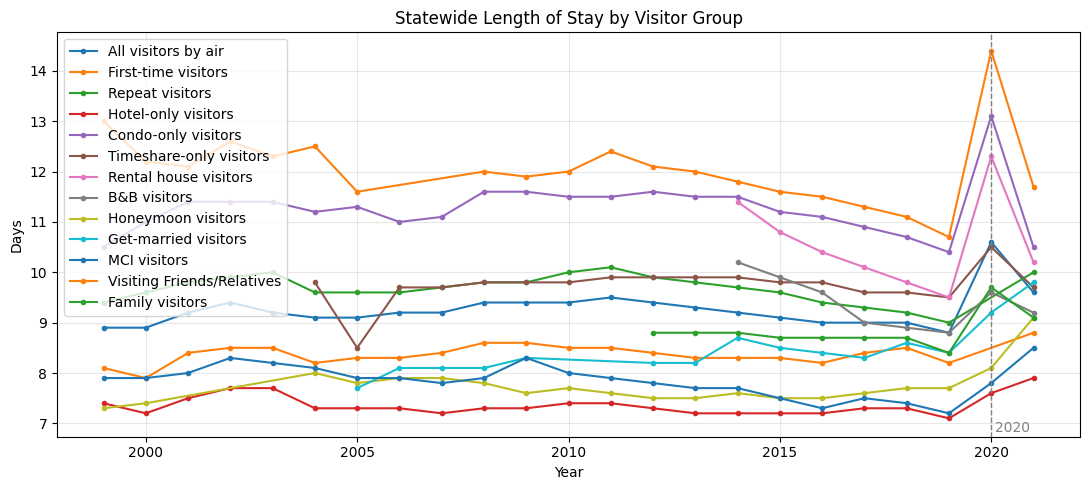

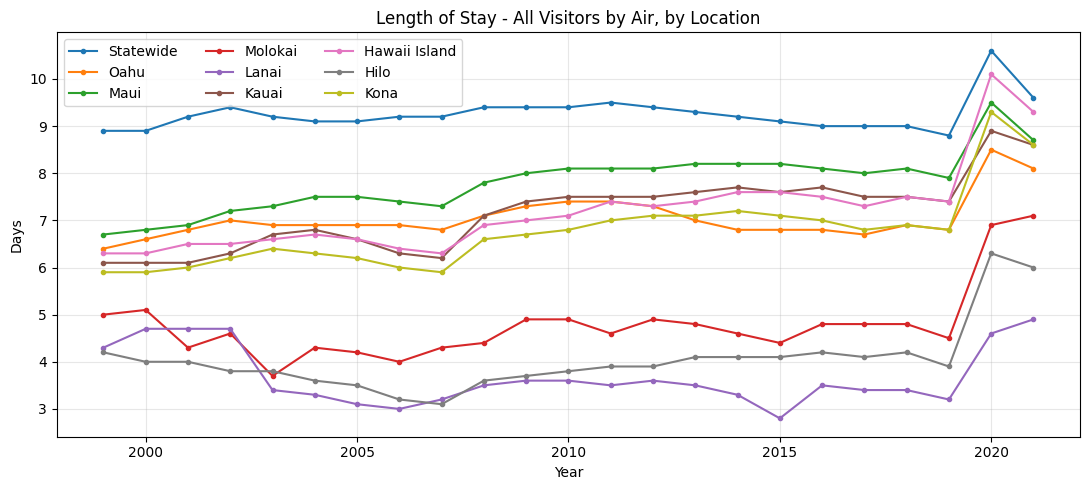

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Done. Files saved: wide CSV, tidy CSV, Excel workbook.


In [ ]:
# ============================================================
# Hawaii Tourism (DBEDT) - Length-of-Stay data cleaner
# Paste into ONE Google Colab cell (or split at the "# ---" lines)
# ============================================================
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- 1. LOAD ------------------------------------------------
try:
    from google.colab import files
    uploaded = files.upload()                      # pick the CSV in the dialog
    fname = next(iter(uploaded))
    raw = pd.read_csv(io.BytesIO(uploaded[fname]))
except ImportError:                                # running outside Colab
    fname = "Hawaii_Tourism_Data__from_DBEDT_Data_Warehouse___1_.csv"
    raw = pd.read_csv(fname)

print(f"Loaded '{fname}': {raw.shape[0]} rows x {raw.shape[1]} cols")

# --- 2. SEPARATE DATA ROWS FROM FOOTNOTES -------------------
# Footnotes sit at the bottom of the file with no Units / values.
is_footnote = raw["Units"].isna()
footnotes   = raw.loc[is_footnote, "Group"].tolist()
df          = raw.loc[~is_footnote].copy()

print("\nFootnotes removed from data table:")
for n in footnotes:
    print("  -", n)

# --- 3. CLEAN TEXT + TYPES ----------------------------------
df.columns = [str(c).strip() for c in df.columns]
for c in ["Group", "Indicator", "Units"]:
    df[c] = df[c].astype(str).str.strip()

year_cols = [c for c in df.columns if c.isdigit()]
df[year_cols] = df[year_cols].apply(pd.to_numeric, errors="coerce")

# "LOS Statewide" / "LOS on Oahu" / "LOS in Hilo" -> clean location name
df["Location"] = (df["Indicator"]
                  .str.replace(r"^LOS\s+(on|in)\s+", "", regex=True)
                  .str.replace(r"^LOS\s+", "", regex=True)
                  .str.strip())
df = df.rename(columns={"Group": "Visitor_Group"})

# --- 4. SORT ORDER (logical, not alphabetical) --------------
location_order = ["Statewide", "Oahu", "Maui", "Molokai", "Lanai",
                  "Kauai", "Hawaii Island", "Hilo", "Kona"]
group_order = ["All visitors by air", "First-time visitors", "Repeat visitors",
               "Hotel-only visitors", "Condo-only visitors",
               "Timeshare-only visitors", "Rental house visitors",
               "B&B visitors", "Honeymoon visitors", "Get-married visitors",
               "MCI visitors", "Visiting Friends/Relatives", "Family visitors"]

# Safety net: anything not in my lists goes at the end instead of vanishing
location_order += [x for x in df["Location"].unique()      if x not in location_order]
group_order    += [x for x in df["Visitor_Group"].unique() if x not in group_order]

df["Location"]      = pd.Categorical(df["Location"],      location_order, ordered=True)
df["Visitor_Group"] = pd.Categorical(df["Visitor_Group"], group_order,    ordered=True)

wide = (df[["Location", "Visitor_Group", "Units"] + year_cols]
        .sort_values(["Location", "Visitor_Group"])
        .reset_index(drop=True))

# --- 5. DATA QUALITY REPORT ---------------------------------
all_empty = wide[wide[year_cols].isna().all(axis=1)]
print(f"\nClean table: {wide.shape[0]} rows")
print(f"Rows with NO data at all (kept, flagged): {len(all_empty)}")
print(f"Total missing cells: {int(wide[year_cols].isna().sum().sum())} "
      f"of {wide[year_cols].size}")

print("\nMissing values per visitor group (count of empty cells):")
print(wide.groupby("Visitor_Group", observed=True)[year_cols]
          .apply(lambda g: g.isna().sum().sum()).to_string())

# Flag completeness per row so you can filter later
wide["Years_With_Data"] = wide[year_cols].notna().sum(axis=1)

# --- 6. TIDY / LONG FORMAT (best for plotting & analysis) ---
tidy = (wide.melt(id_vars=["Location", "Visitor_Group", "Units"],
                  value_vars=year_cols,
                  var_name="Year", value_name="LOS_days")
            .dropna(subset=["LOS_days"])
            .astype({"Year": int})
            .sort_values(["Location", "Visitor_Group", "Year"])
            .reset_index(drop=True))
print(f"\nTidy table: {len(tidy)} populated observations")

# --- 7. QUICK VIEWS -----------------------------------------
# Location x Group matrix for one year
year = "2019"
matrix = wide.pivot(index="Visitor_Group", columns="Location", values=year)
print(f"\nLength of stay (days), {year}:")
print(matrix.round(1).to_string())

# --- 8. PLOTS -----------------------------------------------
# (a) Statewide trend, by group
sw = tidy[(tidy.Location == "Statewide")]
fig, ax = plt.subplots(figsize=(11, 5))
for g, d in sw.groupby("Visitor_Group", observed=True):
    ax.plot(d["Year"], d["LOS_days"], marker="o", ms=3, label=g)
ax.axvline(2020, ls="--", c="grey", lw=1)
ax.text(2020.1, ax.get_ylim()[0] + 0.1, "2020", color="grey")
ax.set(title="Statewide Length of Stay by Visitor Group",
       xlabel="Year", ylabel="Days")
ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

# (b) All-visitors LOS by island/location
av = tidy[tidy.Visitor_Group == "All visitors by air"]
fig, ax = plt.subplots(figsize=(11, 5))
for loc, d in av.groupby("Location", observed=True):
    ax.plot(d["Year"], d["LOS_days"], marker="o", ms=3, label=loc)
ax.set(title="Length of Stay - All Visitors by Air, by Location",
       xlabel="Year", ylabel="Days")
ax.legend(ncol=3); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

# --- 9. EXPORT ----------------------------------------------
wide.to_csv("hawaii_los_clean_wide.csv", index=False)
tidy.to_csv("hawaii_los_clean_tidy.csv", index=False)
with pd.ExcelWriter("hawaii_los_clean.xlsx") as xw:
    wide.to_excel(xw, sheet_name="Wide", index=False)
    tidy.to_excel(xw, sheet_name="Tidy", index=False)
    matrix.to_excel(xw, sheet_name=f"Matrix_{year}")
    pd.DataFrame({"Footnotes": footnotes}).to_excel(xw, sheet_name="Footnotes", index=False)

try:
    files.download("hawaii_los_clean_wide.csv")
    files.download("hawaii_los_clean_tidy.csv")
    files.download("hawaii_los_clean.xlsx")
except NameError:
    pass
print("\nDone. Files saved: wide CSV, tidy CSV, Excel workbook.")